In [ ]:
import pandas as pd

df = pd.read_csv("../outputs/results.csv")

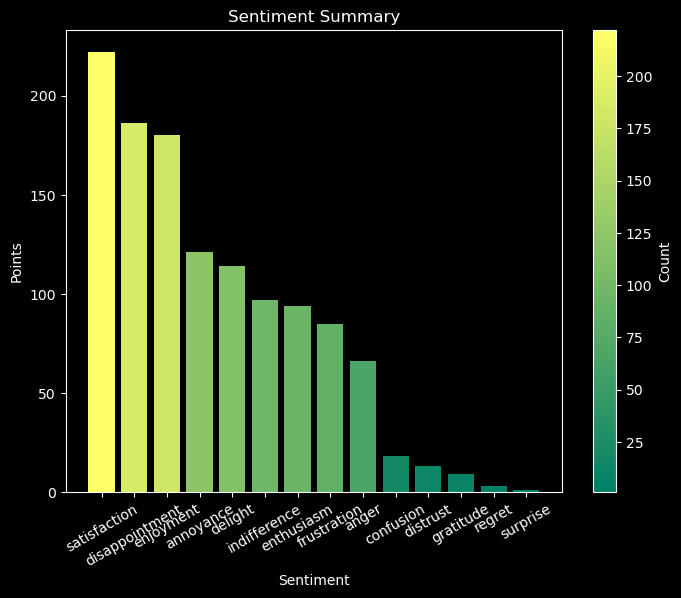

In [65]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

%matplotlib inline

plt.style.use("dark_background")

points = df["s1"].value_counts()*3
for i, col in enumerate(df.columns[2:]):
    points = points.add(df[col].value_counts()*(3-i-1), fill_value=0)

points = points.sort_values(ascending=False)
categories = points.index
values = points.values

norm = mcolors.Normalize(vmin=min(values), vmax=max(values))
cmap = plt.cm.summer
colors = cmap(norm(np.array(values)))

plt.figure(figsize=(8, 6))
plt.xlabel("Sentiment")
plt.xticks(rotation = 30)
plt.ylabel("Points")
plt.title("Sentiment Summary")
plt.bar(categories, points, color=colors)

sm = plt.cm.ScalarMappable(cmap = cmap, norm = norm)
plt.colorbar(sm, ax = plt.gca(), label = "Count")